In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import Ridge
import warnings
warnings.filterwarnings('ignore')



In [2]:
# Load with correct separator (;) and decimal comma (,)
df = pd.read_csv(r"../data/oil_prices.csv", sep=';', decimal=',', encoding='latin1')

print("Dataset shape:", df.shape)
print("\nFirst 3 rows:")
print(df.head(3))
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2569, 17)

First 3 rows:
            date  crude oil ( WTI)  Heating Oil   Conventional Gasoline  \
0  janv 02, 2015             52.72         1.554                  1.378   
1  janv 05, 2015             50.05         1.646                  1.462   
2  janv 06, 2015             47.98         1.709                  1.540   

    RBOB  Ultra-Low Sulfur CARB Diesel  Kerosene-Type Jet Fuel  Propane   \
0  1.586                         1.537                   1.539     0.546   
1  1.667                         1.518                   1.647     0.547   
2  1.750                         1.516                   1.709     0.574   

   Natural GAZ       DJIA    NASDAQ     sp500  bitcoin  USD FUTURE INDEX  \
0        2.889  17,501.65  4,726.81  2,058.20  8,726.2            99.596   
1        2.894  17,371.64  4,652.57  2,020.60  8,916.8            99.768   
2        2.855  17,584.52  4,592.74  2,002.60  8,547.4            98.940   

       gold  Silver   copper  
0  1,184.80  15.8

In [33]:
print(df[['DJIA', 'NASDAQ', 'sp500']].head())

                DJIA   NASDAQ   sp500
date                                 
2015-01-02  17501.65  4726.81  2058.2
2015-01-05  17371.64  4652.57  2020.6
2015-01-06  17584.52  4592.74  2002.6
2015-01-07  17907.87  4650.47  2025.9
2015-01-08  17737.37  4736.19  2062.1


In [4]:
month_map = {
    "janv": "Jan",
    "févr": "Feb",
    "mars": "Mar",
    "avr": "Apr",
    "mai": "May",
    "juin": "Jun",
    "juil": "Jul",
    "août": "Aug",
    "sept": "Sep",
    "oct": "Oct",
    "nov": "Nov",
    "déc": "Dec"
}

# Replace French month names with English ones
for fr, en in month_map.items():
    df['date'] = df['date'].str.replace(fr, en)

# Now parse with the correct format: "Jan 02, 2015"
df['date'] = pd.to_datetime(df['date'], format="%b %d, %Y", errors="coerce")

# Set as index for time series work
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

print("Date range:", df.index.min(), "to", df.index.max())


Date range: 2015-01-02 00:00:00 to 2024-12-31 00:00:00


In [5]:
print("Data types and null counts:")
print(df.info())
print("\nMissing values per column:") 
print(df.isnull().sum()) 
print("\nBasic statistics:")
print(df.describe())

Data types and null counts:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2569 entries, 2015-01-02 to 2024-12-31
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   crude oil ( WTI)              2505 non-null   float64
 1   Heating Oil                   2569 non-null   float64
 2   Conventional Gasoline         2569 non-null   float64
 3    RBOB                         2568 non-null   float64
 4   Ultra-Low Sulfur CARB Diesel  2564 non-null   float64
 5   Kerosene-Type Jet Fuel        2568 non-null   float64
 6   Propane                       2562 non-null   float64
 7   Natural GAZ                   2516 non-null   float64
 8   DJIA                          2516 non-null   object 
 9   NASDAQ                        2516 non-null   object 
 10  sp500                         2516 non-null   object 
 11  bitcoin                       2516 non-null   object 
 12  USD FUTURE INDEX

In [6]:
# Force all object columns to numeric by stripping non-numeric characters
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = (
            df[col].astype(str)
            .str.replace(r"[^\d\.\-]", "", regex=True)
            .replace("", np.nan)
        )
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nNumeric cleaning complete")
print(df.dtypes)


✅ Numeric cleaning complete
crude oil ( WTI)                float64
Heating Oil                     float64
Conventional Gasoline           float64
 RBOB                           float64
Ultra-Low Sulfur CARB Diesel    float64
Kerosene-Type Jet Fuel          float64
Propane                         float64
Natural GAZ                     float64
DJIA                            float64
NASDAQ                          float64
sp500                           float64
bitcoin                         float64
USD FUTURE INDEX                float64
gold                            float64
Silver                          float64
 copper                         float64
dtype: object


In [7]:
categories = {
    "Crude Oil": ["crude oil ( WTI)"],
    "Refined Products": [
        "Heating Oil",
        "Conventional Gasoline",
        " RBOB",
        "Ultra-Low Sulfur CARB Diesel",
        "Kerosene-Type Jet Fuel"
    ],
    "Energy": ["Propane", "Natural GAZ"],
    "Indices": ["DJIA", "NASDAQ", "sp500", "USD FUTURE INDEX"],
    "Crypto & Metals": ["bitcoin", "gold", "Silver", " copper"]
}


print("\nCOMMODITIES BY CATEGORY:")
for category, items in categories.items():
    available = [item for item in items if item in df.columns]
    print(f"\n{category}:")
    for item in available:
        print(f"  ✓ {item}")
    if not available:
        print(f"  ✗ No matching columns found")



📊 COMMODITIES BY CATEGORY:

Crude Oil:
  ✓ crude oil ( WTI)

Refined Products:
  ✓ Conventional Gasoline
  ✓  RBOB
  ✓ Ultra-Low Sulfur CARB Diesel
  ✓ Kerosene-Type Jet Fuel

Energy:
  ✓ Natural GAZ

Indices:
  ✓ DJIA
  ✓ NASDAQ
  ✓ sp500
  ✓ USD FUTURE INDEX

Crypto & Metals:
  ✓ bitcoin
  ✓ gold
  ✓ Silver
  ✓  copper



📈 Creating detailed visualizations...


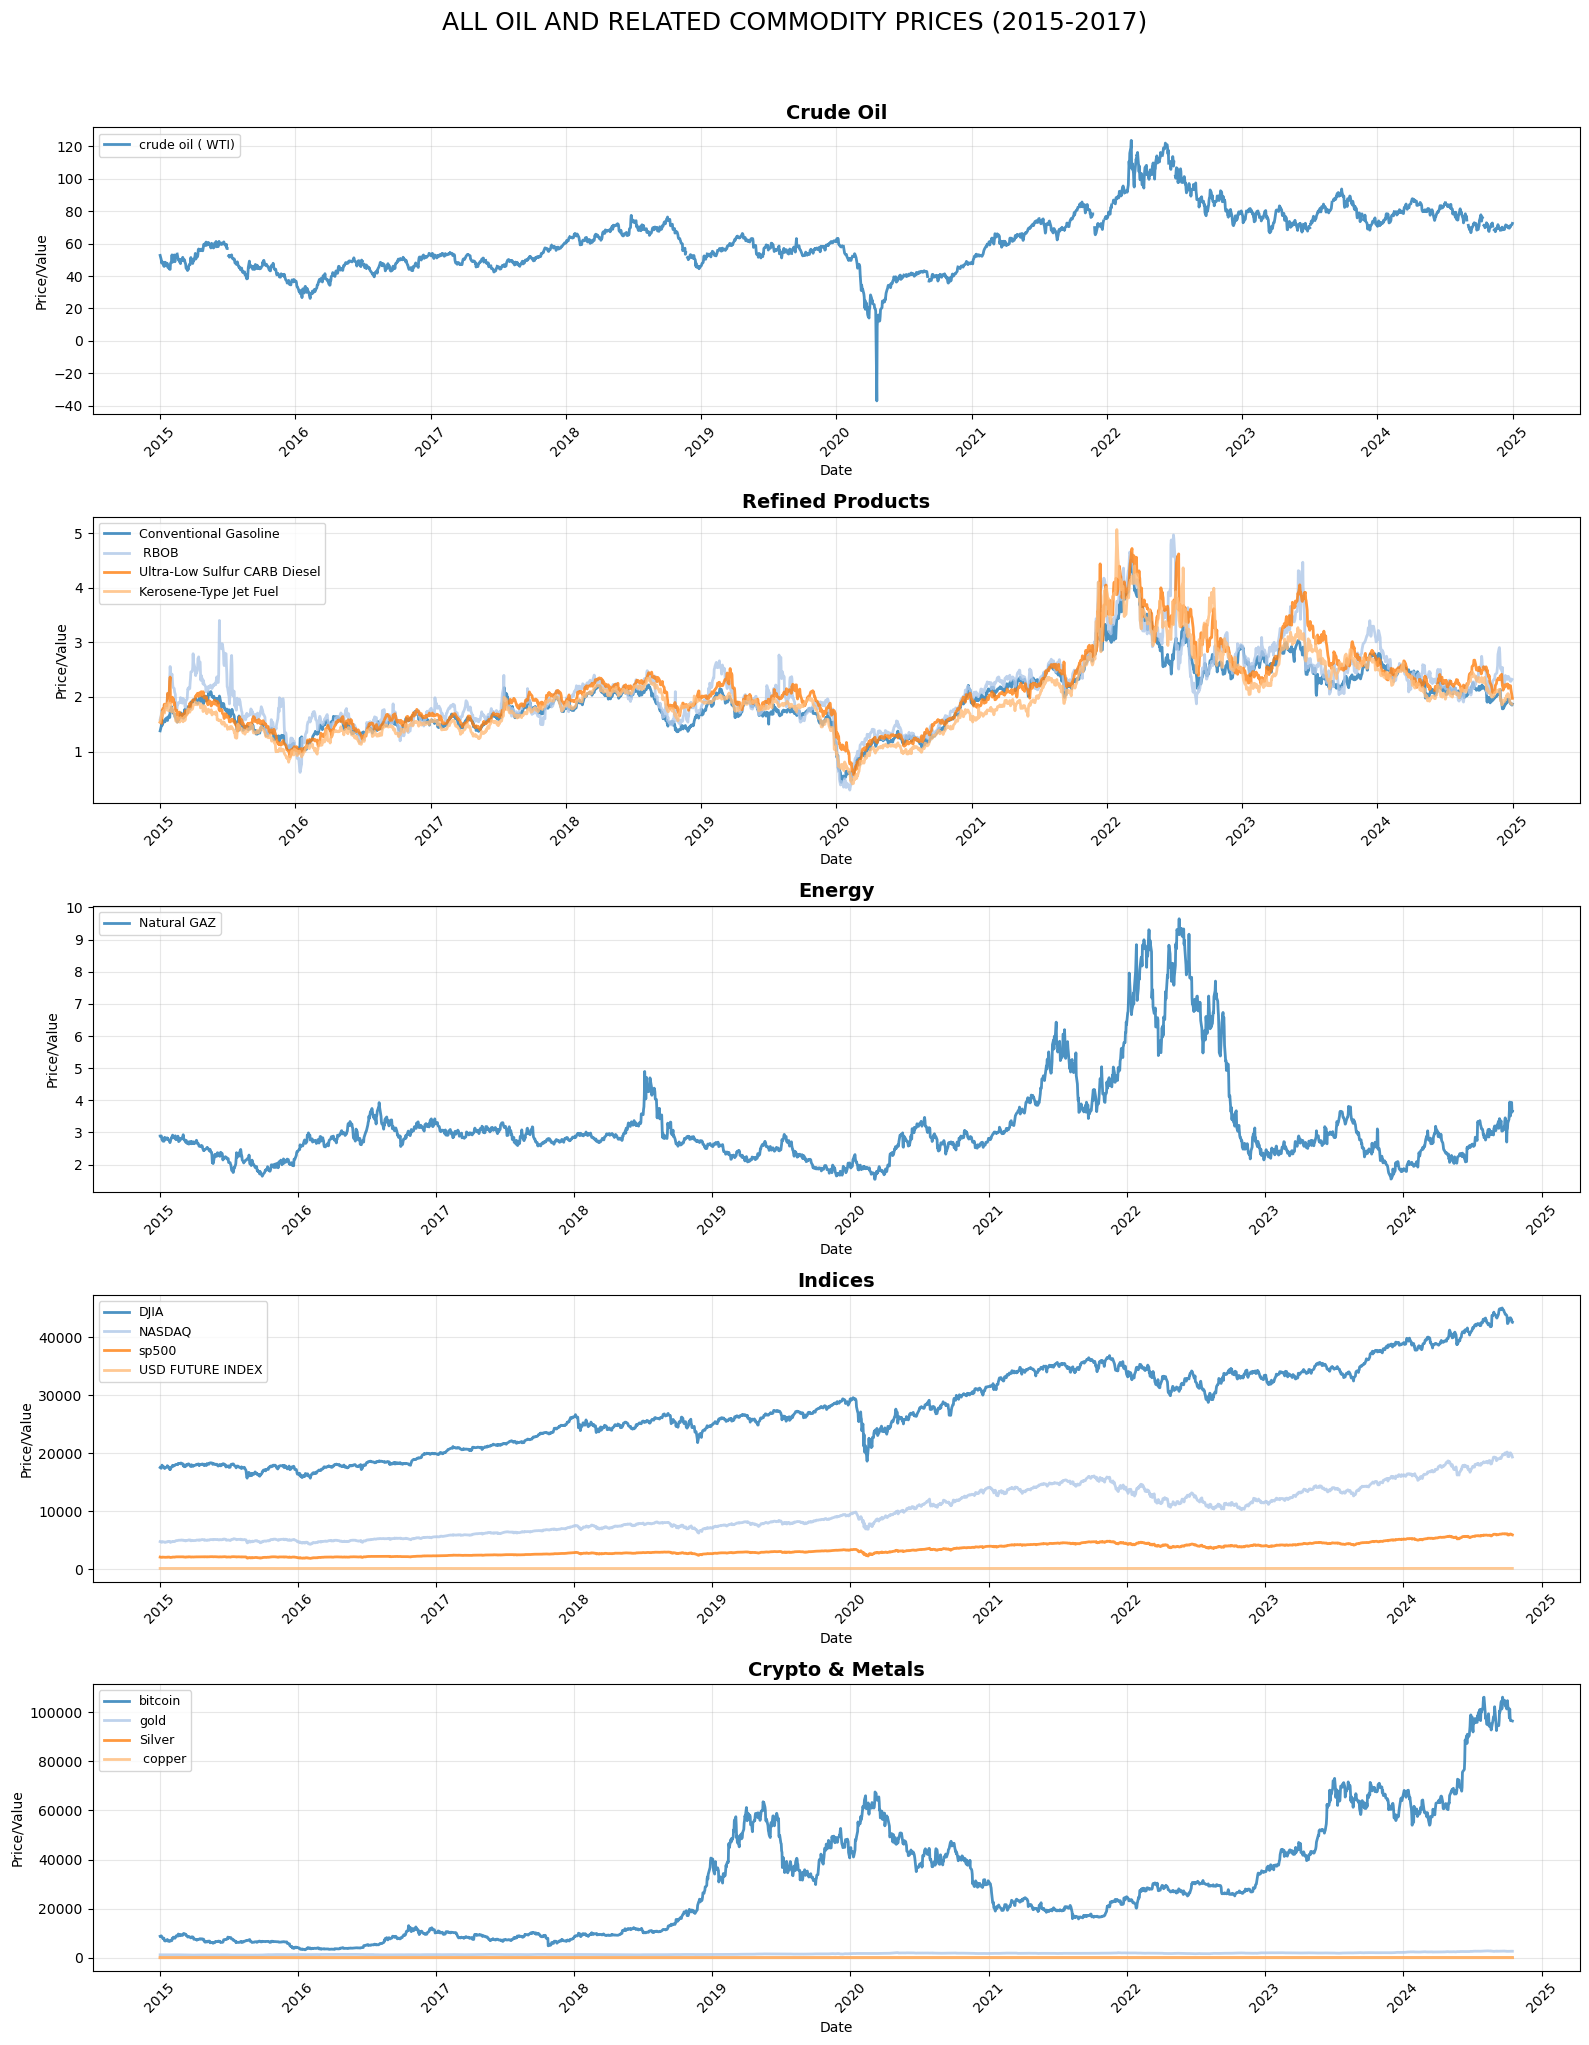

✅ Plot 1: All commodities created for 5 categories


In [8]:
print("\n📈 Creating detailed visualizations...")

categories_with_data = {cat: items for cat, items in categories.items() 
                       if any(item in df.columns for item in items)}

if not categories_with_data:
    print("❌ ERROR: No matching columns found. Check your column names!")
else:
    fig, axes = plt.subplots(len(categories_with_data), 1, figsize=(16, 20))
    if len(categories_with_data) == 1:
        axes = [axes]
    
    fig.suptitle('ALL OIL AND RELATED COMMODITY PRICES (2015-2017)', fontsize=18, y=1.02)
    colors = plt.cm.tab20(np.linspace(0, 1, 20))
    
    for idx, (category, items) in enumerate(categories_with_data.items()):
        ax = axes[idx]
        available_items = [item for item in items if item in df.columns]
        
        if available_items:
            for i, col in enumerate(available_items):
                y = pd.to_numeric(df[col], errors="coerce")  # ensure numeric
                ax.plot(df.index, y, color=colors[i % len(colors)], 
                        linewidth=2, alpha=0.8, label=col)
            
            ax.set_title(f'{category}', fontsize=14, fontweight='bold')
            ax.set_xlabel('Date', fontsize=10)
            ax.set_ylabel('Price/Value', fontsize=10)
            ax.legend(fontsize=9, loc='upper left')
            ax.grid(True, alpha=0.3)
            ax.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
    print(f"Plot 1: All commodities created for {len(categories_with_data)} categories")



🔥 Creating correlation heatmap...


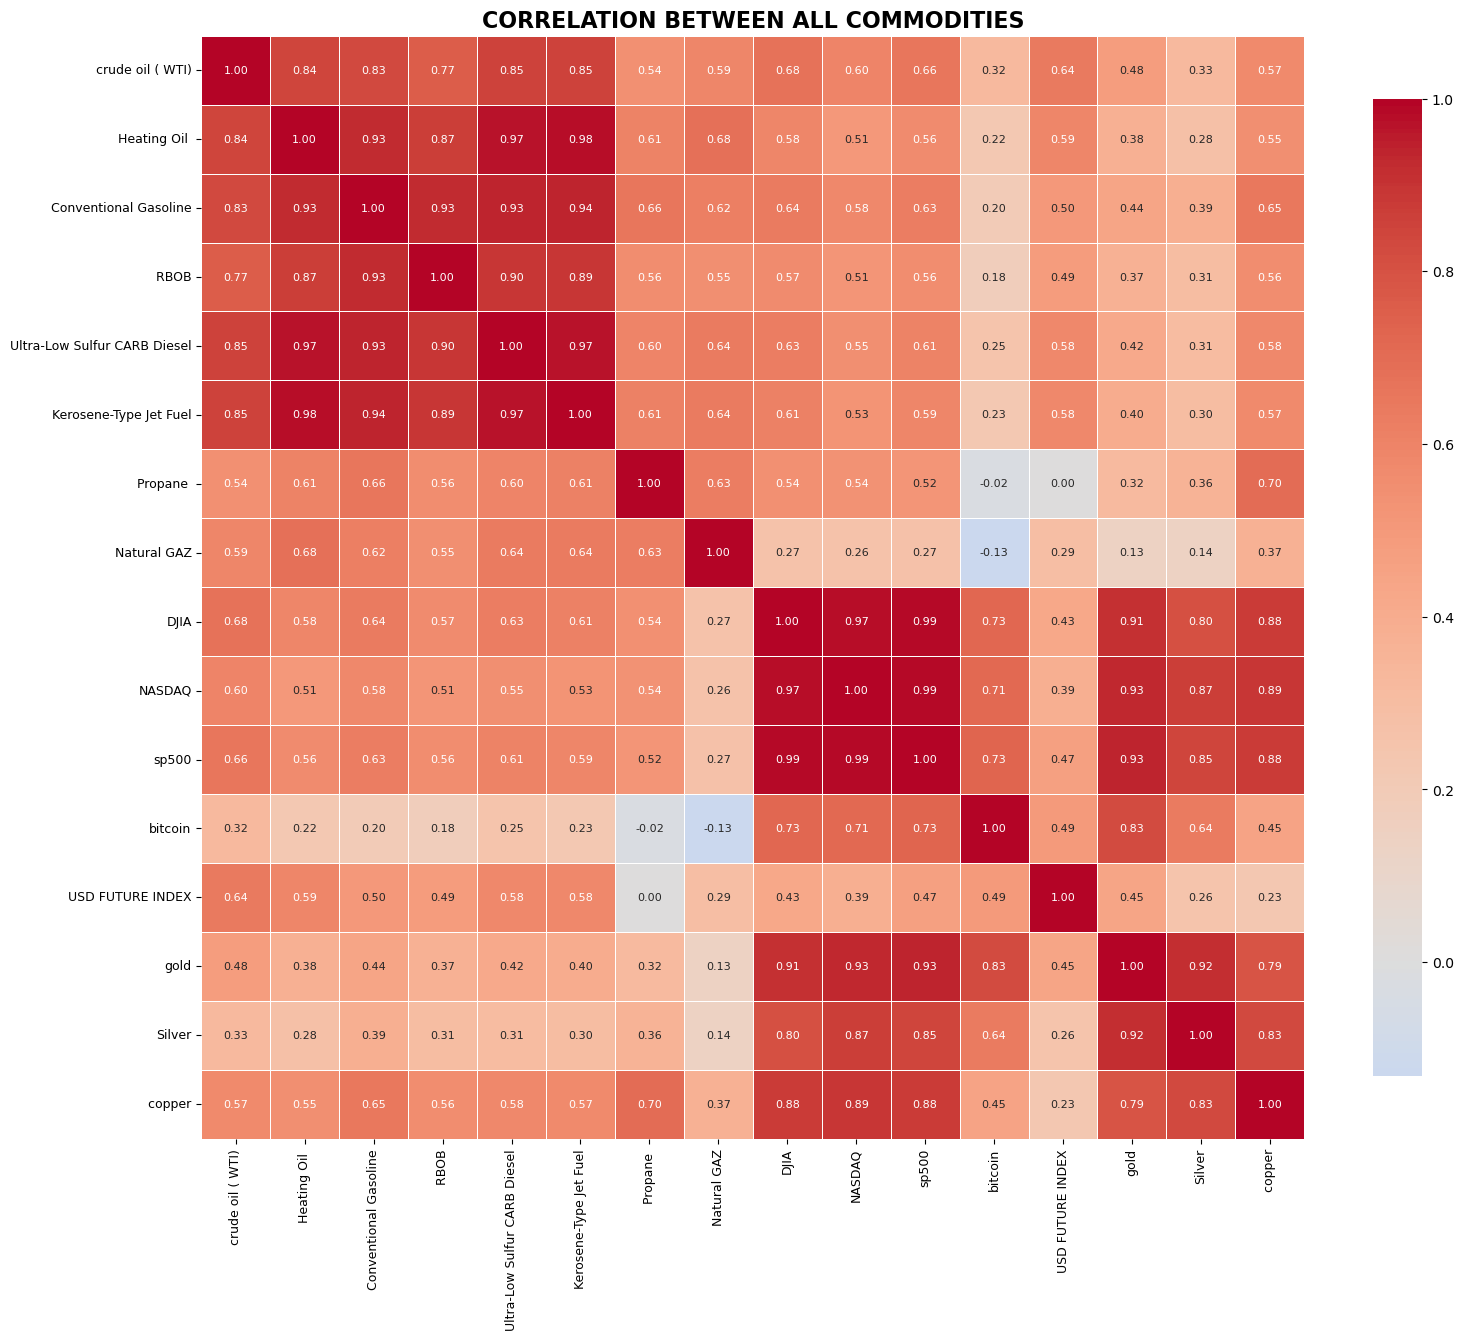

✅ Plot 3: Correlation heatmap created


In [9]:
print("\n🔥 Creating correlation heatmap...")

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_cols) > 1:
    plt.figure(figsize=(16, 14))
    corr_matrix = df[numeric_cols].corr()
    
    sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
                annot_kws={"size": 8})
    
    plt.title('CORRELATION BETWEEN ALL COMMODITIES', fontsize=16, fontweight='bold')
    plt.xticks(rotation=90, fontsize=9)
    plt.yticks(rotation=0, fontsize=9)
    plt.tight_layout()
    plt.show()
    print("Plot 3: Correlation heatmap created")


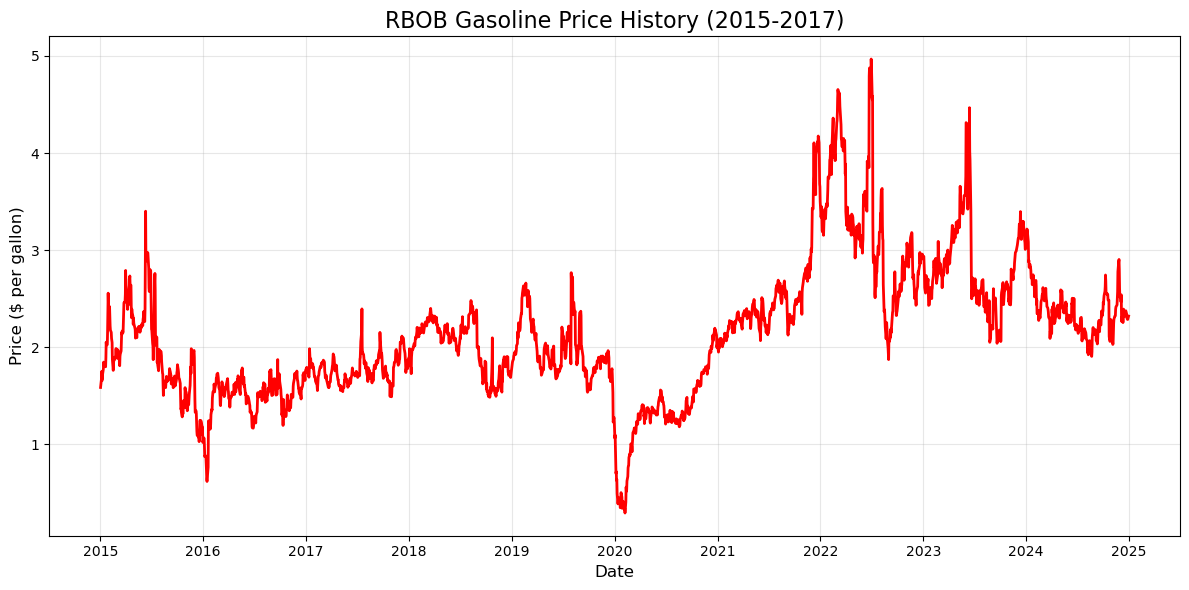

=== RBOB GASOLINE STATISTICS ===
Mean price: $2.14
Highest price: $4.97 on 2022-06-30
Lowest price: $0.29 on 2020-02-07
Current price (last observation): $nan
Total trading days: 2568


In [10]:
# Clean column names by removing leading/trailing spaces
df.columns = df.columns.str.strip()

# Now you can safely use 'RBOB'
if 'RBOB' in df.columns:
    plt.figure(figsize=(12, 6))
    plt.plot(df.index, df['RBOB'], color='red', linewidth=2)
    plt.title('RBOB Gasoline Price History (2015-2017)', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Price ($ per gallon)', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("=== RBOB GASOLINE STATISTICS ===")
    print(f"Mean price: ${df['RBOB'].mean():.2f}")
    print(f"Highest price: ${df['RBOB'].max():.2f} on {df['RBOB'].idxmax().date()}")
    print(f"Lowest price: ${df['RBOB'].min():.2f} on {df['RBOB'].idxmin().date()}")
    print(f"Current price (last observation): ${df['RBOB'].iloc[-1]:.2f}")
    print(f"Total trading days: {len(df['RBOB'].dropna())}")
else:
    print("RBOB column not found. Available columns:")
    print(df.columns.tolist())


In [11]:
df.columns = df.columns.str.strip()

# 2. Print what you actually have
print("Columns after stripping:")
for col in df.columns:
    print(f"  - '{col}'")


Columns after stripping:
  - 'crude oil ( WTI)'
  - 'Heating Oil'
  - 'Conventional Gasoline'
  - 'RBOB'
  - 'Ultra-Low Sulfur CARB Diesel'
  - 'Kerosene-Type Jet Fuel'
  - 'Propane'
  - 'Natural GAZ'
  - 'DJIA'
  - 'NASDAQ'
  - 'sp500'
  - 'bitcoin'
  - 'USD FUTURE INDEX'
  - 'gold'
  - 'Silver'
  - 'copper'


In [12]:
# Clean column names first
df.columns = df.columns.str.strip()

# Define key predictors based on correlation analysis
key_predictors = [
    'RBOB',                              # Target variable
    'Ultra-Low Sulfur CARB Diesel',      # 0.96 correlation
    'Kerosene-Type Jet Fuel',            # 0.89 correlation
    'Conventional Gasoline',             # 0.93 correlation  
    'Heating Oil',                       # 0.87 correlation
    'crude oil ( WTI)'                   # 0.77 correlation
]

# Create working dataset
df_working = df[key_predictors].copy()
print(f"Working dataset created: {df_working.shape}")
print(f"   Date range: {df_working.index.min().date()} to {df_working.index.max().date()}")

✅ Working dataset created: (2569, 6)
   Date range: 2015-01-02 to 2024-12-31


In [13]:
print("\nHandling Missing Values")
print("Missing values before:")
print(df_working.isnull().sum())

# Use modern pandas syntax (ffill/bfill instead of deprecated fillna method)
df_working = df_working.ffill().bfill()

print("\nMissing values after:")
print(df_working.isnull().sum())
print("All missing values handled")


📊 Handling Missing Values
Missing values before:
RBOB                             1
Ultra-Low Sulfur CARB Diesel     5
Kerosene-Type Jet Fuel           1
Conventional Gasoline            0
Heating Oil                      0
crude oil ( WTI)                64
dtype: int64

Missing values after:
RBOB                            0
Ultra-Low Sulfur CARB Diesel    0
Kerosene-Type Jet Fuel          0
Conventional Gasoline           0
Heating Oil                     0
crude oil ( WTI)                0
dtype: int64
✅ All missing values handled


In [14]:
print("\n" + "="*70)
print("FEATURE ENGINEERING")
print("="*70)

# 1. Temporal features
df_working['year'] = df_working.index.year
df_working['month'] = df_working.index.month
df_working['day_of_week'] = df_working.index.dayofweek
df_working['day_of_year'] = df_working.index.dayofyear

# 2. Lagged features (yesterday's prices)
for col in key_predictors[1:]:  # All except RBOB
    df_working[f'{col}_lag1'] = df_working[col].shift(1)

df_working['RBOB_lag1'] = df_working['RBOB'].shift(1)  # For baseline

# 3. Rolling statistics (7-day window)
for col in key_predictors[1:]:
    df_working[f'{col}_ma7'] = df_working[col].rolling(7).mean()
    df_working[f'{col}_std7'] = df_working[col].rolling(7).std()

# 4. Price returns (percentage change)
for col in key_predictors[1:]:
    df_working[f'{col}_return'] = df_working[col].pct_change() * 100

# 5. Advanced features: Price spreads (refining margins)
df_working['RBOB_WTI_spread'] = df_working['RBOB'] - (df_working['crude oil ( WTI)'] / 42)
df_working['RBOB_Conv_spread'] = df_working['RBOB'] - df_working['Conventional Gasoline']

# 6. Seasonal indicators
df_working['is_summer'] = ((df_working['month'] >= 5) & (df_working['month'] <= 8)).astype(int)
df_working['is_winter'] = ((df_working['month'] == 12) | (df_working['month'] <= 2)).astype(int)

# Drop rows with NaN from lag/rolling operations
df_working = df_working.dropna()

print(f"\nFeature engineering complete")
print(f"   Total features created: {df_working.shape[1]}")
print(f"   Rows after cleaning: {df_working.shape[0]}")
print(f"   Date range: {df_working.index.min().date()} to {df_working.index.max().date()}")


FEATURE ENGINEERING

✅ Feature engineering complete
   Total features created: 35
   Rows after cleaning: 2563
   Date range: 2015-01-12 to 2024-12-31


In [15]:
print("\n📍 Creating Target Variable (Tomorrow's RBOB Price)")

# Target: Tomorrow's RBOB price
df_working['RBOB_target'] = df_working['RBOB'].shift(-1)

# Remove last row (no target available)
df_working = df_working.iloc[:-1]

# Separate features and target
feature_columns = [col for col in df_working.columns if col not in ['RBOB', 'RBOB_target']]
X = df_working[feature_columns]
y = df_working['RBOB_target']

print(f"Features (X): {X.shape}")
print(f"Target (y): {y.shape}")
print(f"Modeling period: {X.index.min().date()} to {X.index.max().date()}")


📍 Creating Target Variable (Tomorrow's RBOB Price)
✅ Features (X): (2562, 34)
✅ Target (y): (2562,)
✅ Modeling period: 2015-01-12 to 2024-12-30


In [16]:
print("\nStep 1: Setting Up Walk-Forward Validation")
print("-" * 80)

tscv = TimeSeriesSplit(n_splits=5)
print("Using 5-fold time-series cross-validation")
print("   This simulates real-world progressive deployment")
print("   Each fold trains on all past data, tests on future data\n")



📊 Step 1: Setting Up Walk-Forward Validation
--------------------------------------------------------------------------------
✅ Using 5-fold time-series cross-validation
   This simulates real-world progressive deployment
   Each fold trains on all past data, tests on future data



In [18]:
print("🤖 Step 2: Defining Models")
print("-" * 80)

models = {
    'Baseline (Persistence)': None,
    'Ridge Regression': Ridge(alpha=10.0),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=8,
        min_samples_split=20,
        min_samples_leaf=10,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        random_state=42
    )
}

print(f"{len(models)} models defined\n")


🤖 Step 2: Defining Models
--------------------------------------------------------------------------------
✅ 4 models defined



In [19]:
print("Step 3: Training Across Time Folds")
print("-" * 80)

results = {name: {'mae': [], 'rmse': [], 'r2': [], 'predictions': [], 'actuals': []} 
           for name in models.keys()}
scaler = StandardScaler()

for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
    print(f"\nFold {fold + 1}/5:")
    
    # Split data
    X_train_fold = X.iloc[train_idx]
    X_test_fold = X.iloc[test_idx]
    y_train_fold = y.iloc[train_idx]
    y_test_fold = y.iloc[test_idx]
    
    print(f"  Train: {X_train_fold.index.min().date()} to {X_train_fold.index.max().date()} ({len(X_train_fold)} samples)")
    print(f"  Test:  {X_test_fold.index.min().date()} to {X_test_fold.index.max().date()} ({len(X_test_fold)} samples)")
    
    # Scale features
    X_train_scaled = scaler.fit_transform(X_train_fold)
    X_test_scaled = scaler.transform(X_test_fold)
    X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train_fold.columns, index=X_train_fold.index)
    X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test_fold.columns, index=X_test_fold.index)
    
    # Baseline model (persistence: tomorrow = today)
    y_pred_baseline = X_test_fold['RBOB_lag1'].values
    mae = mean_absolute_error(y_test_fold, y_pred_baseline)
    rmse = np.sqrt(mean_squared_error(y_test_fold, y_pred_baseline))
    r2 = r2_score(y_test_fold, y_pred_baseline)
    results['Baseline (Persistence)']['mae'].append(mae)
    results['Baseline (Persistence)']['rmse'].append(rmse)
    results['Baseline (Persistence)']['r2'].append(r2)
    results['Baseline (Persistence)']['predictions'].extend(y_pred_baseline)
    results['Baseline (Persistence)']['actuals'].extend(y_test_fold.values)
    print(f"  Baseline MAE: ${mae:.4f}")
    
    # Train ML models
    for name, model in models.items():
        if name == 'Baseline (Persistence)':
            continue
        
        model.fit(X_train_scaled, y_train_fold)
        y_pred = model.predict(X_test_scaled)
        
        mae = mean_absolute_error(y_test_fold, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test_fold, y_pred))
        r2 = r2_score(y_test_fold, y_pred)
        
        results[name]['mae'].append(mae)
        results[name]['rmse'].append(rmse)
        results[name]['r2'].append(r2)
        results[name]['predictions'].extend(y_pred)
        results[name]['actuals'].extend(y_test_fold.values)
        
        print(f"  {name} MAE: ${mae:.4f}")


🎯 Step 3: Training Across Time Folds
--------------------------------------------------------------------------------

Fold 1/5:
  Train: 2015-01-12 to 2016-09-09 (427 samples)
  Test:  2016-09-12 to 2018-05-09 (427 samples)
  Baseline MAE: $0.0585
  Ridge Regression MAE: $0.0810
  Random Forest MAE: $0.1833
  Gradient Boosting MAE: $0.0874

Fold 2/5:
  Train: 2015-01-12 to 2018-05-09 (854 samples)
  Test:  2018-05-10 to 2020-01-09 (427 samples)
  Baseline MAE: $0.0827
  Ridge Regression MAE: $0.0558
  Random Forest MAE: $0.1172
  Gradient Boosting MAE: $0.0850

Fold 3/5:
  Train: 2015-01-12 to 2020-01-09 (1281 samples)
  Test:  2020-01-10 to 2021-09-07 (427 samples)
  Baseline MAE: $0.0534
  Ridge Regression MAE: $0.0456
  Random Forest MAE: $0.1254
  Gradient Boosting MAE: $0.1040

Fold 4/5:
  Train: 2015-01-12 to 2021-09-07 (1708 samples)
  Test:  2021-09-08 to 2023-05-03 (427 samples)
  Baseline MAE: $0.1291
  Ridge Regression MAE: $0.0959
  Random Forest MAE: $0.6279
  Gradient Bo

In [20]:
print("\n" + "="*80)
print("FINAL RESULTS: AVERAGE ACROSS ALL FOLDS")
print("="*80)

summary = []
for name in models.keys():
    avg_mae = np.mean(results[name]['mae'])
    std_mae = np.std(results[name]['mae'])
    avg_rmse = np.mean(results[name]['rmse'])
    avg_r2 = np.mean(results[name]['r2'])
    
    summary.append({
        'Model': name,
        'MAE': avg_mae,
        'MAE_std': std_mae,
        'RMSE': avg_rmse,
        'R²': avg_r2
    })

results_df = pd.DataFrame(summary).sort_values('MAE')
baseline_mae = results_df[results_df['Model'] == 'Baseline (Persistence)']['MAE'].values[0]
results_df['Improvement'] = results_df['MAE'].apply(
    lambda x: f"{(1 - x/baseline_mae)*100:+.2f}%" if x != baseline_mae else "0.00%"
)

print("\n" + results_df.to_string(index=False))

# Identify best model
best_model_name = results_df.iloc[0]['Model']
best_mae = results_df.iloc[0]['MAE']
best_improvement = (1 - best_mae/baseline_mae) * 100

print("\n" + "="*80)
print("BEST MODEL")
print("="*80)
print(f"Model: {best_model_name}")
print(f"MAE: ${best_mae:.4f} per gallon")
print(f"Improvement over baseline: {best_improvement:+.2f}%")
print(f"Prediction accuracy: {(1 - best_mae/y.mean())*100:.2f}%")



FINAL RESULTS: AVERAGE ACROSS ALL FOLDS

                 Model      MAE  MAE_std     RMSE       R² Improvement
      Ridge Regression 0.068999 0.017841 0.101704 0.924581     +18.62%
Baseline (Persistence) 0.084791 0.027863 0.126894 0.896918       0.00%
     Gradient Boosting 0.167252 0.147163 0.237230 0.678872     -97.25%
         Random Forest 0.237211 0.196701 0.313345 0.359072    -179.76%

🏆 BEST MODEL
Model: Ridge Regression
MAE: $0.0690 per gallon
Improvement over baseline: +18.62%
Prediction accuracy: 96.78%

FINAL RESULTS: AVERAGE ACROSS ALL FOLDS

                 Model      MAE  MAE_std     RMSE       R² Improvement
      Ridge Regression 0.068999 0.017841 0.101704 0.924581     +18.62%
Baseline (Persistence) 0.084791 0.027863 0.126894 0.896918       0.00%
     Gradient Boosting 0.167252 0.147163 0.237230 0.678872     -97.25%
         Random Forest 0.237211 0.196701 0.313345 0.359072    -179.76%

🏆 BEST MODEL
Model: Ridge Regression
MAE: $0.0690 per gallon
Improvement over ba


📊 CLEAN VISUALIZATION DASHBOARD


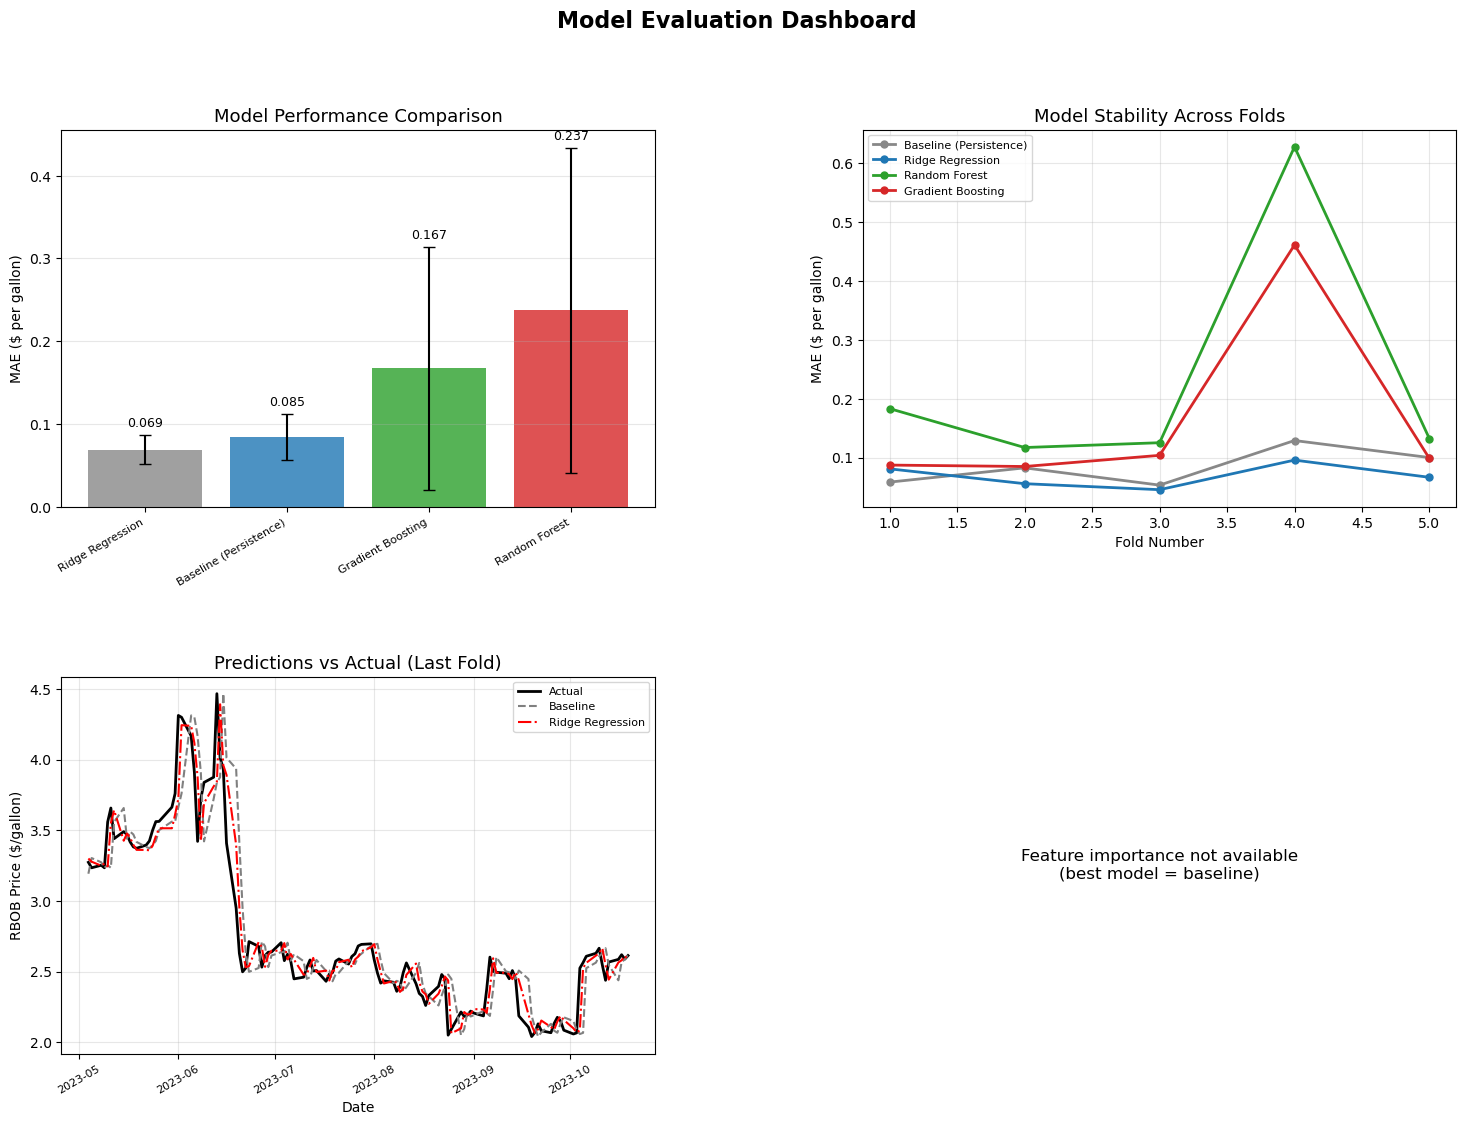

In [27]:
print("\nCLEAN VISUALIZATION DASHBOARD")
print("="*70)

import matplotlib.pyplot as plt
import numpy as np

# ---------------------------------------------------------
# 1. SETUP FIGURE
# ---------------------------------------------------------
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 2, hspace=0.45, wspace=0.35)

title_font = 13
label_font = 10
tick_font = 8

# ---------------------------------------------------------
# 2. PLOT 1 — MODEL PERFORMANCE COMPARISON
# ---------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

models_list = results_df['Model'].tolist()
mae_vals = results_df['MAE'].tolist()
mae_stds = results_df['MAE_std'].tolist()

colors = ['#888888', '#1f77b4', '#2ca02c', '#d62728']

bars = ax1.bar(
    range(len(models_list)), mae_vals,
    yerr=mae_stds, capsize=4,
    color=colors[:len(models_list)], alpha=0.8
)

ax1.set_xticks(range(len(models_list)))
ax1.set_xticklabels(models_list, rotation=30, ha='right', fontsize=tick_font)
ax1.set_ylabel('MAE ($ per gallon)', fontsize=label_font)
ax1.set_title('Model Performance Comparison', fontsize=title_font)
ax1.grid(axis='y', alpha=0.3)

for i, (val, std) in enumerate(zip(mae_vals, mae_stds)):
    ax1.text(i, val + std + 0.01, f'{val:.3f}', ha='center', fontsize=9)

# ---------------------------------------------------------
# 3. PLOT 2 — PERFORMANCE ACROSS FOLDS
# ---------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

for name, color in zip(models.keys(), colors):
    ax2.plot(
        range(1, 6), results[name]['mae'],
        'o-', label=name, color=color, linewidth=2, markersize=5
    )

ax2.set_xlabel('Fold Number', fontsize=label_font)
ax2.set_ylabel('MAE ($ per gallon)', fontsize=label_font)
ax2.set_title('Model Stability Across Folds', fontsize=title_font)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

# ---------------------------------------------------------
# 4. PLOT 3 — ACTUAL VS PREDICTED (LAST FOLD)
# ---------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 0])

# Extract last fold
_, last_test_idx = list(tscv.split(X))[-1]
last_test_dates = X.iloc[last_test_idx].index

n_plot = min(120, len(last_test_idx))
y_actual_last = y.iloc[last_test_idx][:n_plot]
y_pred_baseline_last = X.iloc[last_test_idx]['RBOB_lag1'].values[:n_plot]

# FIX: compute correct start index
fold_sizes = [len(test_idx) for _, test_idx in tscv.split(X)]
start_idx = sum(fold_sizes[:-1])
end_idx = start_idx + n_plot

y_pred_best = results[best_model_name]['predictions'][start_idx:end_idx]

# Plot
ax3.plot(last_test_dates[:n_plot], y_actual_last, label='Actual', color='black', linewidth=2)
ax3.plot(last_test_dates[:n_plot], y_pred_baseline_last, '--', label='Baseline', color='gray')

if best_model_name != 'Baseline (Persistence)':
    ax3.plot(last_test_dates[:n_plot], y_pred_best, '-.', label=best_model_name, color='red')

ax3.set_title(f'Predictions vs Actual (Last Fold)', fontsize=title_font)
ax3.set_xlabel('Date', fontsize=label_font)
ax3.set_ylabel('RBOB Price ($/gallon)', fontsize=label_font)
ax3.legend(fontsize=8)
ax3.grid(alpha=0.3)
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=30, fontsize=tick_font)

# ---------------------------------------------------------
# 5. PLOT 4 — FEATURE IMPORTANCE (ONLY IF APPLICABLE)
# ---------------------------------------------------------
ax4 = fig.add_subplot(gs[1, 1])

if best_model_name != 'Baseline (Persistence)' and 'feature_imp' in locals():
    top_features = feature_imp.head(10)
    ax4.barh(top_features['feature'], top_features['importance'], color='#1f77b4', alpha=0.8)
    ax4.set_title(f'Top Features — {best_model_name}', fontsize=title_font)
    ax4.set_xlabel('Importance Score', fontsize=label_font)
    ax4.tick_params(axis='y', labelsize=8)
    ax4.grid(axis='x', alpha=0.3)
else:
    ax4.text(
        0.5, 0.5,
        "Feature importance not available\n(best model = baseline)",
        ha='center', va='center', fontsize=12
    )
    ax4.axis('off')

# ---------------------------------------------------------
# FINAL LAYOUT
# ---------------------------------------------------------
plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.suptitle("Model Evaluation Dashboard", fontsize=16, fontweight='bold')
plt.show()
